<a href="https://colab.research.google.com/github/SUMIYA-AFRIN33/Wikispeedia_-BiBFS-BFS-A-/blob/main/Wikispeedia_Final_Project_Rearranged_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wikispeedia: BFS vs Bidirectional BFS vs A* Search
Finding the shortest click-path between Wikipedia articles.

- **BFS**: uninformed baseline, always optimal.
- **Bidirectional BFS**: uninformed, searches from both ends, optimal.
- **A\***: informed, guided by a heuristic built from article text (TF-IDF) and article categories.

Run the cells from top to bottom.

## 1. Download the dataset

In [ ]:
import os

if not os.path.exists("wikispeedia_paths-and-graph"):
    print("Downloading paths and graph dataset (9.5 MB)...")
    !wget -q https://snap.stanford.edu/data/wikispeedia/wikispeedia_paths-and-graph.tar.gz
    !tar -xzf wikispeedia_paths-and-graph.tar.gz
    print("Done!")

if not os.path.exists("plaintext_articles"):
    print("Downloading plaintext articles dataset (35 MB)...")
    !wget -q https://snap.stanford.edu/data/wikispeedia/wikispeedia_articles_plaintext.tar.gz
    !tar -xzf wikispeedia_articles_plaintext.tar.gz
    print("Done!")

Done!
Done!


## 2. Load the graph, categories and article text
- `adj`: for each article, the articles it links to (forward links).
- `rev_adj`: for each article, the articles that link to it (needed by Bidirectional BFS).
- `categories`: topic categories (used by the A* heuristic).
- `tfidf_matrix`: numeric text representation of each article (used by the A* heuristic).

In [ ]:
import glob, time, heapq, random, tracemalloc, urllib.parse
from collections import deque, defaultdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer

data_dir = "wikispeedia_paths-and-graph"
unq = urllib.parse.unquote

adj = defaultdict(list)       # outgoing links
rev_adj = defaultdict(list)   # incoming links
n_links = 0
with open(f"{data_dir}/links.tsv", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        u, v = line.strip().split("\t")
        u, v = unq(u), unq(v)
        adj[u].append(v)
        rev_adj[v].append(u)
        n_links += 1

categories = defaultdict(set)
with open(f"{data_dir}/categories.tsv", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        art, cat = line.strip().split("\t")
        art = unq(art)
        parts = cat.split(".")
        for i in range(1, len(parts) + 1):
            categories[art].add(".".join(parts[:i]))

article_texts = {}
for filepath in glob.glob("plaintext_articles/*.txt"):
    art_name = unq(os.path.basename(filepath)[:-4])
    with open(filepath, "r", encoding="utf-8", errors="ignore") as f:
        article_texts[art_name] = f.read()

art_list = list(article_texts.keys())
art_to_idx = {name: i for i, name in enumerate(art_list)}
tfidf_matrix = TfidfVectorizer(stop_words="english", max_features=5000, sublinear_tf=True) \
                   .fit_transform([article_texts[a] for a in art_list])

print(f"Articles with text: {len(art_list)} | Articles with outgoing links: {len(adj)} | Links: {n_links}")
print(f"Average branching factor (links per article): {n_links / len(art_list):.1f}")

Articles with text: 4604 | Articles with outgoing links: 4587 | Links: 119882
Average branching factor (links per article): 26.0


## 3. Dataset overview: links
How many links each article has and which articles are the hubs.

Out-links per article: mean 26.0, median 19, max 294
In-links per article:  mean 26.0, median 8, max 1551
Most linked-to articles: ['United_States', 'United_Kingdom', 'France', 'Europe', 'England', 'World_War_II', 'Germany', 'India']


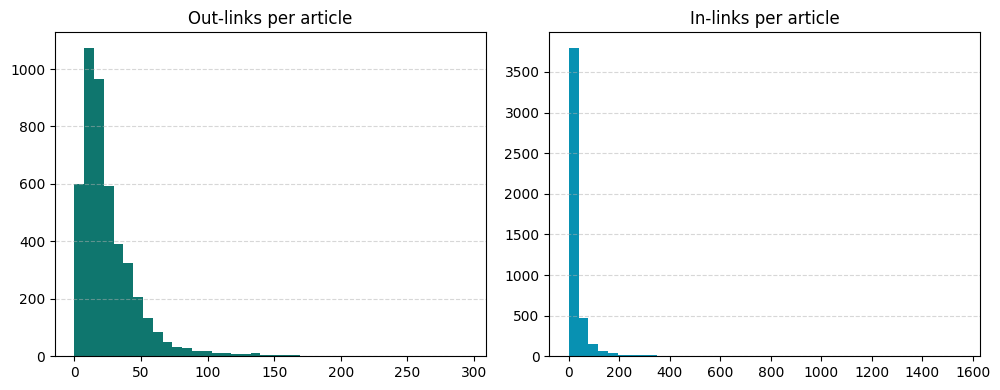

In [ ]:
out_deg = np.array([len(adj[a]) for a in art_list])
in_deg = np.array([len(rev_adj[a]) for a in art_list])
print(f"Out-links per article: mean {out_deg.mean():.1f}, median {np.median(out_deg):.0f}, max {out_deg.max()}")
print(f"In-links per article:  mean {in_deg.mean():.1f}, median {np.median(in_deg):.0f}, max {in_deg.max()}")
print("Most linked-to articles:", sorted(art_list, key=lambda a: len(rev_adj[a]), reverse=True)[:8])

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].hist(out_deg, bins=40, color="#0F766E"); ax[0].set_title("Out-links per article")
ax[1].hist(in_deg, bins=40, color="#0891B2"); ax[1].set_title("In-links per article")
for a in ax:
    a.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("dataset_overview.png", dpi=200)
plt.show()

## 4. The three algorithms
All three return `(path, nodes_expanded)`. A *node expanded* means one article whose outgoing links were examined.

In [ ]:
def build_path(parent, u):
    path = []
    while u is not None:
        path.append(u)
        u = parent[u]
    return path[::-1]

# ---------------- 1. Standard BFS (uninformed, optimal) ----------------
def standard_bfs(start, goal):
    if start == goal:
        return [start], 0
    parent = {start: None}
    queue = deque([start])
    expanded = 0
    while queue:
        u = queue.popleft()
        expanded += 1
        if u == goal:
            return build_path(parent, u), expanded
        for v in adj[u]:
            if v not in parent:
                parent[v] = u
                queue.append(v)
    return None, expanded

# ---------------- 2. Bidirectional BFS (uninformed, optimal) ----------------
# Expands one FULL level at a time from the smaller side; this guarantees the shortest path.
def bidirectional_bfs(start, goal):
    if start == goal:
        return [start], 0
    f_parent, b_parent = {start: None}, {goal: None}
    f_dist, b_dist = {start: 0}, {goal: 0}
    f_front, b_front = [start], [goal]
    expanded = 0

    while f_front and b_front:
        forward = len(f_front) <= len(b_front)
        if forward:
            frontier, dist, other, graph, parent = f_front, f_dist, b_dist, adj, f_parent
        else:
            frontier, dist, other, graph, parent = b_front, b_dist, f_dist, rev_adj, b_parent

        nxt_front, best, meet = [], None, None
        for u in frontier:
            expanded += 1
            for v in graph[u]:
                if v not in dist:
                    dist[v] = dist[u] + 1
                    parent[v] = u
                    nxt_front.append(v)
                if v in other:
                    total = dist[u] + 1 + other[v]
                    if best is None or total < best:
                        best, meet = total, (u, v)

        if forward: f_front = nxt_front
        else:       b_front = nxt_front

        if best is not None:
            u, v = meet
            if not forward:
                u, v = v, u
            left = build_path(f_parent, u)
            right, x = [], v
            while x is not None:
                right.append(x)
                x = b_parent[x]
            return left + right, expanded
    return None, expanded

# ---------------- 3. A* Search (informed) ----------------
# h(n) = 1 - (0.5 * category_similarity + 0.5 * text_similarity)   (0 = very close to the goal)
# f(n) = g(n) + W * h(n)      W scales the heuristic (larger W = more guided, faster, less safe)
W_DEFAULT = 2.5

def astar_search(start, goal, W=W_DEFAULT):
    if start == goal:
        return [start], 0
    # Text similarity of EVERY article to the goal, computed once per search
    text_sims = None
    if goal in art_to_idx:
        text_sims = (tfidf_matrix @ tfidf_matrix[art_to_idx[goal]].T).toarray().ravel()
    goal_cats = categories.get(goal, set())
    h_cache = {}

    def h(node):
        if node in h_cache:
            return h_cache[node]
        c1 = categories.get(node, set())
        cat_sim = len(c1 & goal_cats) / len(c1 | goal_cats) if (c1 and goal_cats) else 0.0
        text_sim = text_sims[art_to_idx[node]] if (text_sims is not None and node in art_to_idx) else 0.0
        h_cache[node] = 1.0 - (0.5 * cat_sim + 0.5 * text_sim)
        return h_cache[node]

    g = {start: 0}
    parent = {start: None}
    open_list = [(W * h(start), 0, start)]
    expanded = 0
    while open_list:
        f, gc, u = heapq.heappop(open_list)
        if gc > g[u]:          # outdated queue entry
            continue
        expanded += 1
        if u == goal:
            return build_path(parent, u), expanded
        for v in adj[u]:
            ng = gc + 1
            if ng < g.get(v, float("inf")):
                g[v] = ng
                parent[v] = u
                heapq.heappush(open_list, (ng + W * h(v), ng, v))
    return None, expanded

## 5. Example routes and their solution paths
Shows the actual article-by-article paths each algorithm finds (useful for the report's *Result* section).

In [ ]:
demo_routes = [("Bangladesh", "Computer"), ("Asteroid", "Viking"), ("Brain", "Telephone"),
               ("Pyramid", "Bean"), ("Theatre", "Zebra")]

rows = []
for start, goal in demo_routes:
    out = {"Route": f"{start} -> {goal}"}
    for name, fn in [("BFS", standard_bfs), ("Bi-BFS", bidirectional_bfs), ("A*", astar_search)]:
        t0 = time.perf_counter()
        path, exp = fn(start, goal)
        out[f"{name} clicks"] = len(path) - 1
        out[f"{name} nodes"] = exp
        out[f"{name} ms"] = round((time.perf_counter() - t0) * 1000, 2)
        out[f"{name} path"] = " -> ".join(path)
    rows.append(out)

demo = pd.DataFrame(rows)
display(demo[["Route"] + [c for c in demo.columns if c.endswith(("clicks", "nodes", "ms"))]])
for r in rows:
    print(r["Route"])
    print("  BFS   :", r["BFS path"])
    print("  Bi-BFS:", r["Bi-BFS path"])
    print("  A*    :", r["A* path"])

,Route,BFS clicks,BFS nodes,BFS ms,Bi-BFS clicks,Bi-BFS nodes,Bi-BFS ms,A* clicks,A* nodes,A* ms
0,Bangladesh -> Computer,3,1115,9.58,3,52,0.70,3,11,41.82
1,Asteroid -> Viking,3,791,6.91,3,21,0.45,3,22,43.85
2,Brain -> Telephone,3,990,7.84,3,45,1.01,3,74,42.61
3,Pyramid -> Bean,3,2038,13.34,3,19,0.56,3,10,21.02
4,Theatre -> Zebra,3,2262,14.85,3,14,0.31,3,16,23.50


Bangladesh -> Computer
  BFS   : Bangladesh -> Arsenic -> 20th_century -> Computer
  Bi-BFS: Bangladesh -> Arsenic -> 20th_century -> Computer
  A*    : Bangladesh -> Sanskrit -> ASCII -> Computer
Asteroid -> Viking
  BFS   : Asteroid -> 1_Ceres -> Paris -> Viking
  Bi-BFS: Asteroid -> 1_Ceres -> Paris -> Viking
  A*    : Asteroid -> Earth -> Middle_Ages -> Viking
Brain -> Telephone
  BFS   : Brain -> Algorithm -> Computer -> Telephone
  Bi-BFS: Brain -> Biology -> 19th_century -> Telephone
  A*    : Brain -> Algorithm -> Computer -> Telephone
Pyramid -> Bean
  BFS   : Pyramid -> California -> Fruit -> Bean
  Bi-BFS: Pyramid -> California -> Fruit -> Bean
  A*    : Pyramid -> California -> Vegetable -> Bean
Theatre -> Zebra
  BFS   : Theatre -> India -> Extinction -> Zebra
  Bi-BFS: Theatre -> India -> Extinction -> Zebra
  A*    : Theatre -> India -> Mammal -> Zebra


## 6. Main experiment: 200 routes taken from real human games
The start and target of each game in `paths_finished.tsv` become a test route (random seed 42, so the routes are the same every run).

In [ ]:
finished = pd.read_csv(f"{data_dir}/paths_finished.tsv", sep="\t", comment="#", header=None,
                       names=["ip", "timestamp", "duration", "path", "rating"])

random.seed(42)
valid = set(art_list)
pairs = set()
for p in finished["path"]:
    clicks = [unq(t) for t in p.split(";") if t != "<"]
    s, t = clicks[0], clicks[-1]
    if s != t and s in valid and t in valid:
        pairs.add((s, t, len(clicks) - 1))
pairs = random.sample(sorted(pairs), 200)
print("Test routes:", len(pairs))

rows = []
for s, t, human in pairs:
    rec = {"start": s, "goal": t, "human_len": human}
    for name, fn in [("BFS", standard_bfs), ("A*", astar_search), ("BiBFS", bidirectional_bfs)]:
        t0 = time.perf_counter()
        path, exp = fn(s, t)
        rec[f"{name}_time"] = time.perf_counter() - t0
        rec[f"{name}_exp"] = exp
        rec[f"{name}_len"] = len(path) - 1 if path else np.nan
    rows.append(rec)

df_res = pd.DataFrame(rows).dropna().reset_index(drop=True)
df_res["A*_optimal"] = df_res["A*_len"] == df_res["BFS_len"]
df_res["BiBFS_optimal"] = df_res["BiBFS_len"] == df_res["BFS_len"]

summary = pd.DataFrame({
    "Avg path length (clicks)": [df_res["human_len"].mean(), df_res["BFS_len"].mean(),
                                 df_res["BiBFS_len"].mean(), df_res["A*_len"].mean()],
    "Avg nodes expanded": [np.nan, df_res["BFS_exp"].mean(), df_res["BiBFS_exp"].mean(), df_res["A*_exp"].mean()],
    "Avg time (ms)": [np.nan, df_res["BFS_time"].mean() * 1000, df_res["BiBFS_time"].mean() * 1000,
                      df_res["A*_time"].mean() * 1000],
    "Optimal paths (%)": [np.nan, 100.0, df_res["BiBFS_optimal"].mean() * 100, df_res["A*_optimal"].mean() * 100],
}, index=["Human players", "BFS", "Bidirectional BFS", "A*"]).round(2)
summary

Test routes: 200


,Avg path length (clicks),Avg nodes expanded,Avg time (ms),Optimal paths (%)
Human players,5.30,NaN,NaN,NaN
BFS,2.77,1408.94,14.69,100.0
Bidirectional BFS,2.77,13.72,0.45,100.0
A*,2.82,64.94,57.15,95.5


## 7. Charts

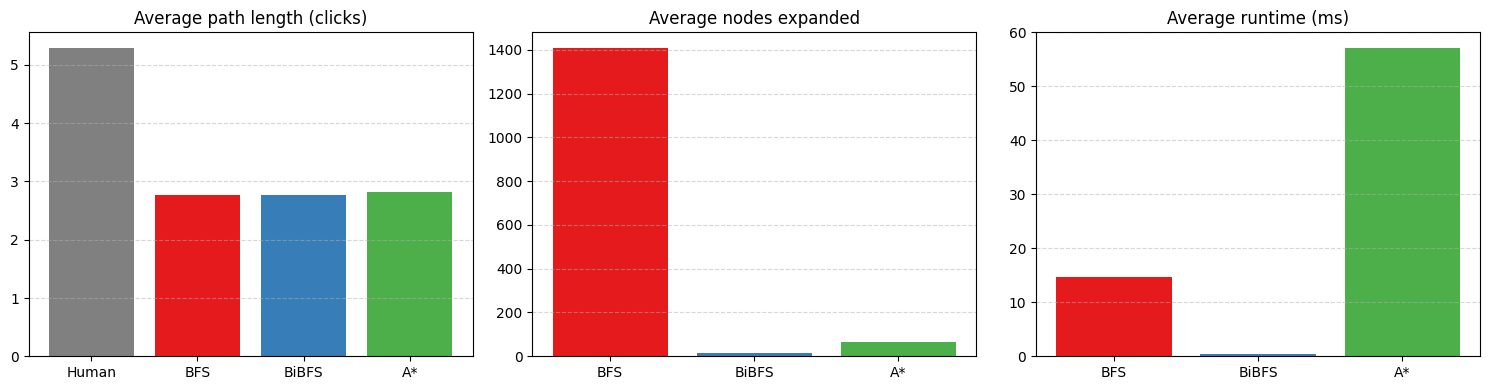

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
labels = ["BFS", "BiBFS", "A*"]
colors = ["#e41a1c", "#377eb8", "#4daf4a"]

ax[0].bar(["Human"] + labels, [df_res["human_len"].mean()] + [df_res[f"{l}_len"].mean() for l in labels],
          color=["gray"] + colors)
ax[0].set_title("Average path length (clicks)")
ax[1].bar(labels, [df_res[f"{l}_exp"].mean() for l in labels], color=colors)
ax[1].set_title("Average nodes expanded")
ax[2].bar(labels, [df_res[f"{l}_time"].mean() * 1000 for l in labels], color=colors)
ax[2].set_title("Average runtime (ms)")
for a in ax:
    a.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("comparison.png", dpi=200)
plt.show()

## 8. Correctness check
Bidirectional BFS must never return a longer path than BFS.

In [ ]:
bad_bi = df_res[df_res["BiBFS_len"] != df_res["BFS_len"]]
bad_as = df_res[df_res["A*_len"] != df_res["BFS_len"]]
print(f"Bidirectional BFS differs from BFS on {len(bad_bi)} of {len(df_res)} routes (should be 0)")
print(f"A* differs from BFS on {len(bad_as)} of {len(df_res)} routes (longer path = heuristic is not guaranteed optimal)")
if len(bad_as):
    print(bad_as[["start", "goal", "BFS_len", "A*_len"]].head(10))

Bidirectional BFS differs from BFS on 0 of 200 routes (should be 0)
A* differs from BFS on 9 of 200 routes (longer path = heuristic is not guaranteed optimal)
                  start                  goal  BFS_len  A*_len
18           All_Blacks              Palm_oil        3       4
72         Windows_2000           Whale_shark        3       4
77    Quantum_mechanics                  Clay        2       3
101         Tin_whistle                 Cloud        2       3
115            Calculus                  Fire        2       3
117             Crystal                  Orca        3       4
146                Wind                   Owl        3       4
153  Water_purification  Ludwig_van_Beethoven        3       4
157           Cambridge                 Kenya        2       3


## 9. Verification against the official distance matrix
The dataset ships the true shortest distance for every pair of articles. If BFS is correct, its path lengths must equal these values.

In [ ]:
# The authors computed the true shortest distance between every pair of articles (Floyd-Warshall).
# Rows and columns are in the same order as articles.tsv, one digit per pair, "_" = unreachable.
art_order = []
with open(f"{data_dir}/articles.tsv", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        art_order.append(unq(line.strip()))
art_pos = {name: i for i, name in enumerate(art_order)}

dist_rows = []
with open(f"{data_dir}/shortest-path-distance-matrix.txt", "r", encoding="utf-8") as f:
    for line in f:
        if line.startswith("#") or not line.strip():
            continue
        dist_rows.append(line.strip())
print(f"Official distance matrix: {len(dist_rows)} rows x {len(dist_rows[0])} columns")

def official_distance(s, t):
    ch = dist_rows[art_pos[s]][art_pos[t]]
    return np.nan if ch == "_" else int(ch)

df_res["official_len"] = [official_distance(s, t) for s, t in zip(df_res["start"], df_res["goal"])]
verify = pd.DataFrame({
    "Matches official distance (%)": [(df_res[f"{k}_len"] == df_res["official_len"]).mean() * 100
                                      for k in ["BFS", "BiBFS", "A*"]]
}, index=["BFS", "Bidirectional BFS", "A*"]).round(1)
verify

Official distance matrix: 4604 rows x 4604 columns


,Matches official distance (%)
BFS,100.0
Bidirectional BFS,100.0
A*,95.5


## 10. Unfinished games (extra analysis)
Games where players gave up (`timeout` or `restart`). Are the abandoned routes the harder ones, measured by their true shortest distance?

Unfinished games: 24875
type
restart    15552
timeout     9323
Average shortest distance of the assigned route - finished games: 2.85, unfinished games: 3.23


,finished,unfinished,quit rate (%)
shortest distance (clicks),,,
1.0,1172,105,8.2
2.0,13078,2812,17.7
3.0,30018,14537,32.6
4.0,6579,6164,48.4
5.0,430,1067,71.3
6.0,29,138,82.6
7.0,0,16,100.0


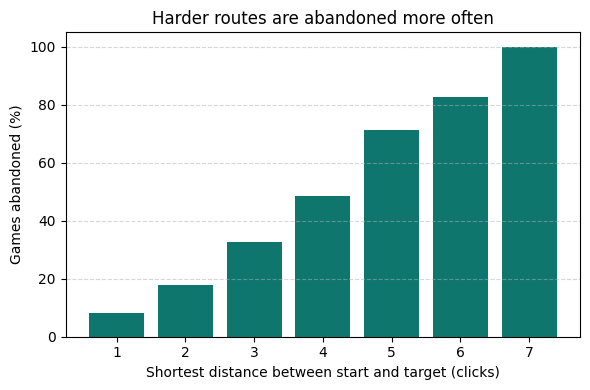

In [ ]:
unfinished = pd.read_csv(f"{data_dir}/paths_unfinished.tsv", sep="\t", comment="#", header=None,
                         names=["ip", "timestamp", "duration", "path", "target", "type"])
print("Unfinished games:", len(unfinished))
print(unfinished["type"].value_counts().to_string())

def shortest_distances(pairs):
    return pd.Series([official_distance(s, t) for s, t in pairs if s in art_pos and t in art_pos], dtype="float")

fin_pairs = []
for p in finished["path"]:
    clicks = [unq(t) for t in p.split(";") if t != "<"]
    fin_pairs.append((clicks[0], clicks[-1]))
unf_pairs = [(unq(p.split(";")[0]), unq(t)) for p, t in zip(unfinished["path"], unfinished["target"])]
d_fin, d_unf = shortest_distances(fin_pairs), shortest_distances(unf_pairs)

print(f"Average shortest distance of the assigned route - finished games: {d_fin.mean():.2f}, unfinished games: {d_unf.mean():.2f}")

quit_table = pd.DataFrame({"finished": d_fin.value_counts(), "unfinished": d_unf.value_counts()}).fillna(0).astype(int).sort_index()
quit_table["quit rate (%)"] = (quit_table["unfinished"] / (quit_table["finished"] + quit_table["unfinished"]) * 100).round(1)
quit_table = quit_table[quit_table.index >= 1]      # ignore the few games where start = target
quit_table.index.name = "shortest distance (clicks)"
display(quit_table)

plt.figure(figsize=(6, 4))
plt.bar(quit_table.index.astype(int).astype(str), quit_table["quit rate (%)"], color="#0F766E")
plt.xlabel("Shortest distance between start and target (clicks)")
plt.ylabel("Games abandoned (%)")
plt.title("Harder routes are abandoned more often")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout(); plt.savefig("unfinished.png", dpi=200); plt.show()

## 11. Statistical comparison
Mean ± standard deviation over the 200 routes, and a paired Wilcoxon signed-rank test (same routes, so the samples are paired).

In [ ]:
import pandas as pd
from scipy.stats import wilcoxon

def mean_sd(col, scale=1):
    return f"{df_res[col].mean() * scale:.2f} ± {df_res[col].std() * scale:.2f}"

algos = [("BFS", "BFS"), ("Bidirectional BFS", "BiBFS"), ("A*", "A*")]
stats_table = pd.DataFrame({
    "Path length (clicks)": [mean_sd(f"{k}_len") for _, k in algos],
    "Nodes expanded": [mean_sd(f"{k}_exp") for _, k in algos],
    "Time (ms)": [mean_sd(f"{k}_time", 1000) for _, k in algos],
}, index=[n for n, _ in algos])
display(stats_table)          # mean ± standard deviation over the routes

def p_value(a, b, metric):
    try:
        p = wilcoxon(df_res[f"{a}_{metric}"], df_res[f"{b}_{metric}"]).pvalue
        return "<0.0001" if p < 0.0001 else f"{p:.4f}"
    except ValueError:        # all differences are zero
        return "identical"

tests = pd.DataFrame(
    [[f"{x} vs {y}", p_value(kx, ky, "exp"), p_value(kx, ky, "time")]
     for (x, kx), (y, ky) in [(algos[1], algos[0]), (algos[1], algos[2]), (algos[2], algos[0])]],
    columns=["Comparison", "P value (nodes expanded)", "P value (time)"])
tests          # paired Wilcoxon signed-rank test on the same 200 routes

,Path length (clicks),Nodes expanded,Time (ms)
BFS,2.77 ± 0.73,1408.94 ± 1032.98,14.69 ± 17.20
Bidirectional BFS,2.77 ± 0.73,13.72 ± 14.98,0.45 ± 0.96
A*,2.81 ± 0.74,64.94 ± 162.60,57.15 ± 46.95


,Comparison,P value (nodes expanded),P value (time)
0,Bidirectional BFS vs BFS,<0.0001,<0.0001
1,Bidirectional BFS vs A*,<0.0001,<0.0001
2,A* vs BFS,<0.0001,<0.0001


## 12. Human vs shortest path lengths
How many clicks people needed compared with the true shortest path, over the same 200 routes.

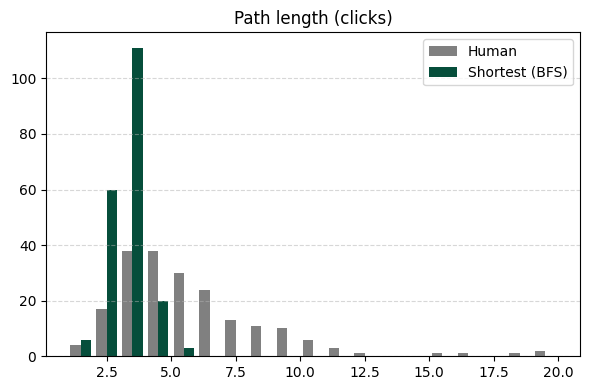

In [ ]:
top = int(max(df_res["human_len"].max(), df_res["BFS_len"].max())) + 2
plt.figure(figsize=(6, 4))
plt.hist([df_res["human_len"], df_res["BFS_len"]], bins=range(1, top), label=["Human", "Shortest (BFS)"],
         color=["gray", "#064E3B"])
plt.title("Path length (clicks)")
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("path_lengths.png", dpi=200)
plt.show()

## 13. Results by path length
Average nodes expanded as the shortest path gets longer (does the gap between algorithms grow?).

In [ ]:
by_depth = df_res.groupby("BFS_len")[["BFS_exp", "BiBFS_exp", "A*_exp"]].mean().round(1)
by_depth.insert(0, "routes", df_res.groupby("BFS_len").size())
by_depth.index.name = "shortest path (clicks)"
by_depth

,routes,BFS_exp,BiBFS_exp,A*_exp
shortest path (clicks),,,,
1,6,20.2,1.0,2.0
2,60,456.6,2.0,7.8
3,111,1647.0,16.5,37.9
4,20,2995.4,35.0,252.0
5,3,3850.7,30.0,1088.0


## 14. Memory usage
Peak extra memory used during one search, measured with `tracemalloc` on the first 30 routes (measured separately because tracing slows the code down).

,Avg peak memory (KB)
BFS,144.4
BiBFS,35.5
A*,195.5


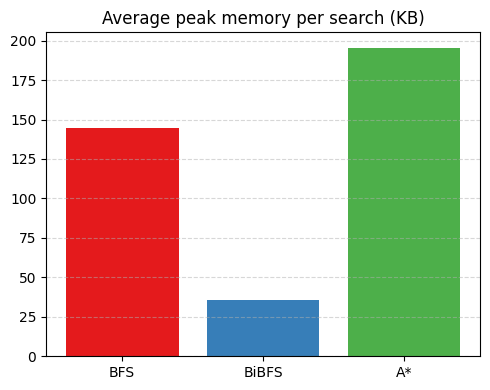

In [ ]:
mem_rows = []
for s, t in zip(df_res["start"][:30], df_res["goal"][:30]):
    rec = {}
    for name, fn in [("BFS", standard_bfs), ("BiBFS", bidirectional_bfs), ("A*", astar_search)]:
        tracemalloc.start()
        fn(s, t)
        rec[name] = tracemalloc.get_traced_memory()[1] / 1024   # peak, in KB
        tracemalloc.stop()
    mem_rows.append(rec)

mem = pd.DataFrame(mem_rows)
mem_summary = mem.mean().round(1).rename("Avg peak memory (KB)").to_frame()
display(mem_summary)

plt.figure(figsize=(5, 4))
plt.bar(mem.columns, mem.mean(), color=colors)
plt.title("Average peak memory per search (KB)")
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.savefig("memory.png", dpi=200)
plt.show()

## 15. Heuristic weight experiment (A*)
How does the heuristic weight `W` change A*? Tested on 50 routes. `W = 0` means no heuristic (A* becomes plain Dijkstra, which behaves like BFS).

In [ ]:
sub = df_res.head(50)
w_rows = []
for W in [0, 1, 2.5, 5]:
    exps, times, opt = [], [], 0
    for s, t, bfs_len in zip(sub["start"], sub["goal"], sub["BFS_len"]):
        t0 = time.perf_counter()
        path, exp = astar_search(s, t, W=W)
        times.append(time.perf_counter() - t0)
        exps.append(exp)
        opt += (len(path) - 1) == bfs_len
    w_rows.append({"W": W, "Avg nodes expanded": np.mean(exps),
                   "Avg time (ms)": np.mean(times) * 1000, "Optimal paths (%)": opt / len(sub) * 100})
pd.DataFrame(w_rows).round(2)

,W,Avg nodes expanded,Avg time (ms),Optimal paths (%)
0,0.0,1647.68,79.29,100.0
1,1.0,837.52,43.00,100.0
2,2.5,95.00,28.85,98.0
3,5.0,39.62,26.96,72.0


## 16. Visualization of the solution paths
The paths found by the three algorithms for one example route, drawn as a graph.

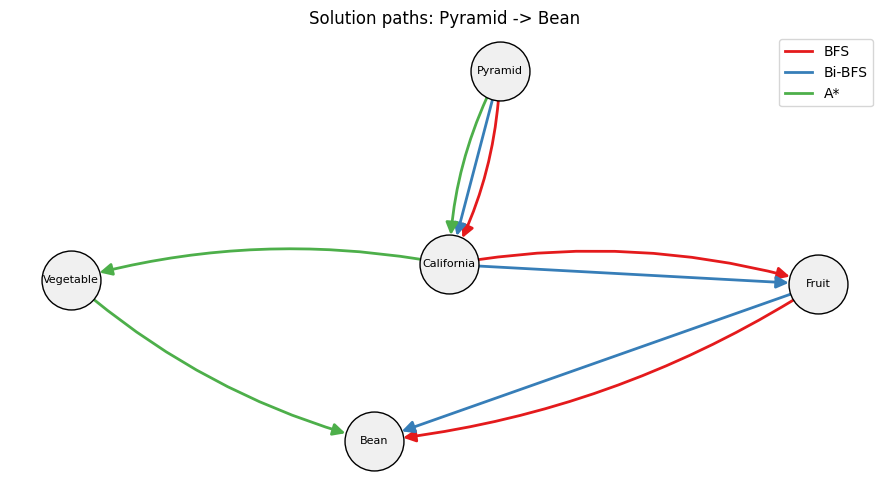

In [ ]:
import networkx as nx

start, goal = "Pyramid", "Bean"
paths = {"BFS": standard_bfs(start, goal)[0],
         "Bi-BFS": bidirectional_bfs(start, goal)[0],
         "A*": astar_search(start, goal)[0]}

G = nx.DiGraph()
edge_color = {"BFS": "#e41a1c", "Bi-BFS": "#377eb8", "A*": "#4daf4a"}
for name, p in paths.items():
    for a, b in zip(p, p[1:]):
        G.add_edge(a, b)

pos = nx.spring_layout(G, seed=3, k=1.2)
plt.figure(figsize=(9, 5))
nx.draw_networkx_nodes(G, pos, node_color="#f0f0f0", edgecolors="black", node_size=1800)
nx.draw_networkx_labels(G, pos, font_size=8)
for i, (name, p) in enumerate(paths.items()):
    nx.draw_networkx_edges(G, pos, edgelist=list(zip(p, p[1:])), edge_color=edge_color[name],
                           width=2, arrows=True, arrowsize=18, node_size=1800,
                           connectionstyle=f"arc3,rad={0.12 * (i - 1)}", label=name)
plt.title(f"Solution paths: {start} -> {goal}")
plt.legend(handles=[plt.Line2D([0], [0], color=c, lw=2, label=n) for n, c in edge_color.items()])
plt.axis("off")
plt.tight_layout()
plt.savefig("paths.png", dpi=200)
plt.show()

## 17. NLP extension: sentence embeddings as the A* heuristic
Replace TF-IDF text similarity with sentence embeddings (SBERT `all-MiniLM-L6-v2`) and compare the two A* versions. Run on a GPU runtime if possible.

In [ ]:
!pip -q install sentence-transformers
from sentence_transformers import SentenceTransformer

model = SentenceTransformer("all-MiniLM-L6-v2")
texts = [article_texts[a][:2000] for a in art_list]       # the model reads about the first 256 words
emb = model.encode(texts, batch_size=64, show_progress_bar=True, normalize_embeddings=True)
print("Embedding matrix:", emb.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 90.9MB            

... (5 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/72 [00:00<?, ?it/s]

Embedding matrix: (4604, 384)


In [ ]:
def astar_nlp(start, goal, W=W_DEFAULT):
    """A* where the text part of the heuristic uses sentence embeddings instead of TF-IDF."""
    if start == goal:
        return [start], 0
    sims = None
    if goal in art_to_idx:
        sims = np.clip(emb @ emb[art_to_idx[goal]], 0, 1)      # cosine similarity (vectors are normalized)
    goal_cats = categories.get(goal, set())
    h_cache = {}

    def h(node):
        if node in h_cache:
            return h_cache[node]
        c1 = categories.get(node, set())
        cat_sim = len(c1 & goal_cats) / len(c1 | goal_cats) if (c1 and goal_cats) else 0.0
        text_sim = sims[art_to_idx[node]] if (sims is not None and node in art_to_idx) else 0.0
        h_cache[node] = 1.0 - (0.5 * cat_sim + 0.5 * text_sim)
        return h_cache[node]

    g = {start: 0}
    parent = {start: None}
    open_list = [(W * h(start), 0, start)]
    expanded = 0
    while open_list:
        f, gc, u = heapq.heappop(open_list)
        if gc > g[u]:
            continue
        expanded += 1
        if u == goal:
            return build_path(parent, u), expanded
        for v in adj[u]:
            ng = gc + 1
            if ng < g.get(v, float("inf")):
                g[v] = ng
                parent[v] = u
                heapq.heappush(open_list, (ng + W * h(v), ng, v))
    return None, expanded

In [ ]:
rows = []
for s, t in zip(df_res["start"], df_res["goal"]):
    t0 = time.perf_counter()
    path, exp = astar_nlp(s, t)
    rows.append({"NLP_len": len(path) - 1 if path else np.nan, "NLP_exp": exp,
                 "NLP_time": time.perf_counter() - t0})
nlp = pd.DataFrame(rows)
df_res[["A*NLP_len", "A*NLP_exp", "A*NLP_time"]] = nlp.values

compare = pd.DataFrame({
    "Avg path length (clicks)": [df_res["BFS_len"].mean(), df_res["A*_len"].mean(), df_res["A*NLP_len"].mean()],
    "Avg nodes expanded": [df_res["BFS_exp"].mean(), df_res["A*_exp"].mean(), df_res["A*NLP_exp"].mean()],
    "Avg time (ms)": [df_res["BFS_time"].mean() * 1000, df_res["A*_time"].mean() * 1000, df_res["A*NLP_time"].mean() * 1000],
    "Optimal paths (%)": [100.0, (df_res["A*_len"] == df_res["BFS_len"]).mean() * 100,
                          (df_res["A*NLP_len"] == df_res["BFS_len"]).mean() * 100],
}, index=["BFS (baseline)", "A* + TF-IDF", "A* + sentence embeddings (NLP)"]).round(2)
compare

,Avg path length (clicks),Avg nodes expanded,Avg time (ms),Optimal paths (%)
BFS (baseline),2.77,1408.94,14.69,100.0
A* + TF-IDF,2.82,64.94,57.15,95.5
A* + sentence embeddings (NLP),2.84,58.29,11.38,92.5


## 18. NLP extension for Bidirectional BFS: embedding-guided beam
Plain Bidirectional BFS has no heuristic, so NLP can only help it by choosing *which* frontier nodes to expand. Here each side keeps only its `k` nodes most similar (sentence embeddings) to the opposite end. This needs the `emb` matrix from section 17. It is faster but no longer guaranteed optimal, so we measure how often it still finds the shortest path.

In [ ]:
def bidirectional_bfs_nlp(start, goal, beam=20):
    """Bidirectional BFS that keeps only the `beam` most promising nodes of the frontier it is about to expand.
    Promising = embedding similarity to the OPPOSITE end (goal for the forward side, start for the backward side).
    Not guaranteed optimal: pruned nodes are never expanded."""
    if start == goal:
        return [start], 0
    f_parent, b_parent = {start: None}, {goal: None}
    f_dist, b_dist = {start: 0}, {goal: 0}
    f_front, b_front = [start], [goal]
    expanded = 0

    def keep_best(nodes, ref):
        if len(nodes) <= beam or ref not in art_to_idx:
            return nodes
        ref_vec = emb[art_to_idx[ref]]
        sims = np.array([emb[art_to_idx[n]] @ ref_vec if n in art_to_idx else -1.0 for n in nodes])
        return [nodes[i] for i in np.argsort(-sims)[:beam]]

    while f_front and b_front:
        forward = len(f_front) <= len(b_front)
        if forward:
            f_front = keep_best(f_front, goal)
            frontier, dist, other, graph, parent = f_front, f_dist, b_dist, adj, f_parent
        else:
            b_front = keep_best(b_front, start)
            frontier, dist, other, graph, parent = b_front, b_dist, f_dist, rev_adj, b_parent

        nxt_front, best, meet = [], None, None
        for u in frontier:
            expanded += 1
            for v in graph[u]:
                if v not in dist:
                    dist[v] = dist[u] + 1
                    parent[v] = u
                    nxt_front.append(v)
                if v in other:
                    total = dist[u] + 1 + other[v]
                    if best is None or total < best:
                        best, meet = total, (u, v)

        if forward: f_front = nxt_front
        else:       b_front = nxt_front

        if best is not None:
            u, v = meet
            if not forward:
                u, v = v, u
            left = build_path(f_parent, u)
            right, x = [], v
            while x is not None:
                right.append(x)
                x = b_parent[x]
            return left + right, expanded
    return None, expanded


In [ ]:
beams = [5, 10, 20, 50]
rows = []
for beam in beams:
    lens, exps, times = [], [], []
    for s, t in zip(df_res["start"], df_res["goal"]):
        t0 = time.perf_counter()
        path, exp = bidirectional_bfs_nlp(s, t, beam=beam)
        times.append(time.perf_counter() - t0)
        exps.append(exp)
        lens.append(len(path) - 1 if path else np.nan)
    lens = np.array(lens, dtype=float)
    rows.append({"Method": f"Bidirectional BFS + NLP beam (k={beam})",
                 "Avg path length (clicks)": np.nanmean(lens),
                 "Avg nodes expanded": np.mean(exps),
                 "Avg time (ms)": np.mean(times) * 1000,
                 "Optimal paths (%)": np.mean(lens == df_res["BFS_len"].values) * 100,
                 "No path found": int(np.isnan(lens).sum())})

nlp_bi = pd.DataFrame(rows).set_index("Method")
base = pd.DataFrame({
    "Avg path length (clicks)": [df_res["BFS_len"].mean(), df_res["BiBFS_len"].mean()],
    "Avg nodes expanded": [df_res["BFS_exp"].mean(), df_res["BiBFS_exp"].mean()],
    "Avg time (ms)": [df_res["BFS_time"].mean() * 1000, df_res["BiBFS_time"].mean() * 1000],
    "Optimal paths (%)": [100.0, (df_res["BiBFS_len"] == df_res["BFS_len"]).mean() * 100],
    "No path found": [0, 0],
}, index=["BFS (baseline)", "Bidirectional BFS (plain)"])
pd.concat([base, nlp_bi]).round(2)


,Avg path length (clicks),Avg nodes expanded,Avg time (ms),Optimal paths (%),No path found
BFS (baseline),2.77,1408.94,14.69,100.0,0
Bidirectional BFS (plain),2.77,13.72,0.45,100.0,0
Bidirectional BFS + NLP beam (k=5),2.80,5.95,0.22,96.5,0
Bidirectional BFS + NLP beam (k=10),2.78,8.43,0.19,99.0,0
Bidirectional BFS + NLP beam (k=20),2.77,11.44,0.20,100.0,0
Bidirectional BFS + NLP beam (k=50),2.77,13.46,0.30,100.0,0
